## Dataset

This notebook loads the cleaned Spotify Music Features dataset for our **Spotify Over Time** project.

- **Source:** [Spotify Music Features Dataset](https://www.kaggle.com/datasets/amith1707/spotify-music-features-dataset) (Kaggle)
- **Cleaned/sampled version:** 150,000 rows, 24 columns
- **How it was generated:** see `data/clean_data.py` in the [GitHub repo](https://github.com/CS122-04-FA26/spotifyOverTime-Spotify-music) - it filters out rows missing core audio features, removes duplicates, and keeps audio features, decade/era labels, genre/mood fields, and decade-level trend aggregates
- **Loaded directly from GitHub (via Git LFS)** in the cell below


In [ ]:
import pandas as pd
url = 'https://media.githubusercontent.com/media/CS122-04-FA26/spotifyOverTime-Spotify-music/main/data/cleaned_csv.csv'
df = pd.read_csv(url)
df.head()

,track_id,track_popularity,energy,valence,danceability,acousticness,instrumentalness,speechiness,liveness,loudness,...,era,genre_l1,mood_cluster,emotional_arc,mean_energy_by_decade,mean_valence_by_decade,mean_tempo_by_decade,mean_loudness_by_decade,acousticness_decline_idx,danceability_trend
0,spotify:track:3fWToJxr4IgjDtilBxzygL,2,0.577,0.0643,0.462,0.239000,0.00213,0.0373,0.1860,-11.061,...,2011-2020,Electronic,melancholic_6,Q2_angry,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672
1,spotify:track:0BgQOOuUXRvn38H8xoxOIV,0,0.138,0.0301,0.155,0.878000,0.84800,0.0562,0.1430,-23.744,...,2021+,Pop,sad_slow,Q3_depressed,0.632695,0.426118,121.802360,-9.080332,0.323613,0.549115
2,spotify:track:4NQbVoIjeKYbf2ivOSuO9B,1,0.435,0.0382,0.485,0.771000,0.00457,0.0313,0.1710,-8.759,...,2000-2010,Rock,melancholic,Q3_depressed,0.631259,0.487966,120.716660,-9.304721,0.333616,0.531136
3,spotify:track:3XeFCWwUkalXOxGxHYiPqM,6,0.899,0.0606,0.570,0.000332,0.59100,0.0550,0.1300,-1.630,...,2011-2020,Electronic,angry_intense,Q2_angry,0.651554,0.440806,121.858284,-8.588164,0.305663,0.542672
4,spotify:track:0MFKRZDU8bEkHSf4wegHnZ,0,0.940,0.2730,0.592,0.000018,0.83900,0.0533,0.0515,-7.470,...,2000-2010,Electronic,angry_intense,Q2_angry,0.631259,0.487966,120.716660,-9.304721,0.333616,0.531136


In [9]:
import pandas as pd
url = 'https://media.githubusercontent.com/media/CS122-04-FA26/spotifyOverTime-Spotify-music/main/data/cleaned_csv.csv'
df = pd.read_csv(url)

print('--- DataFrame Info ---')
df.info()

print('\n--- Missing Values Per Column ---')
print(df.isnull().sum())

print('\n--- Summary Statistics (Numerical Columns) ---')
print(df.describe())

print('\n--- Column Names ---')
print(df.columns.tolist())

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 24 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   track_id                  150000 non-null  object 
 1   track_popularity          150000 non-null  int64  
 2   energy                    150000 non-null  float64
 3   valence                   150000 non-null  float64
 4   danceability              150000 non-null  float64
 5   acousticness              150000 non-null  float64
 6   instrumentalness          150000 non-null  float64
 7   speechiness               150000 non-null  float64
 8   liveness                  150000 non-null  float64
 9   loudness                  150000 non-null  float64
 10  tempo                     150000 non-null  float64
 11  key                       150000 non-null  int64  
 12  mode                      150000 non-null  int64  
 13  decade               

In [10]:
# Define the correct chronological order for eras
era_order = ['<2000', '2000-2010', '2011-2020', '2021+']

# Reindex the grouped dataframe to match the chronological order
era_trends_chronological = era_trends.reindex(era_order)

print("--- Chronologically Ordered Core Audio Features Mean by Era ---")
print(era_trends_chronological)

--- Chronologically Ordered Core Audio Features Mean by Era ---
             energy   valence  danceability  acousticness
era                                                      
<2000      0.653112  0.601277      0.628476      0.166614
2000-2010  0.635626  0.486143      0.530754      0.328624
2011-2020  0.648501  0.436377      0.543949      0.307940
2021+      0.630879  0.426250      0.547095      0.325212


### Key Insights from Music Trends Over Time

By ordering the eras chronologically (`<2000`, `2000-2010`, `2011-2020`, `2021+`), we observe several prominent shifts in core audio features over time:

1. **Valence Decline:** Music has become progressively less positive/cheerful. The average valence was at its highest before 2000 (0.601) and has steadily declined to its lowest in the 2021+ era (0.426), reflecting a potential shift towards more melancholic, introspective, or moody musical characteristics.
2. **Energy Fluctuations:** Energy levels peaked before 2000 (0.653), dipped slightly during 2000-2010, rose again in 2011-2020 (0.649), and have stabilized or dropped slightly in the recent 2021+ era (0.631).
3. **Danceability and Acousticness Dynamics:**
   - Average danceability dropped from `<2000` (0.628) to `2000-2010` (0.531) but has been steadily recovering since, currently standing at 0.547 for the `2021+` era.
   - Acousticness experienced a notable rise from pre-2000 (0.167) to the 21st-century eras (0.308 to 0.329), showing that modern catalog entries include significantly more acoustic properties compared to older eras.

In [5]:
print('=== Genre Distribution (genre_l1) ===')
genre_counts = df['genre_l1'].value_counts()
genre_pct = df['genre_l1'].value_counts(normalize=True) * 100
genre_dist = pd.DataFrame({'Counts': genre_counts, 'Percentage (%)': genre_pct})
print(genre_dist)

print('\n=== Mood Cluster Distribution (mood_cluster) ===')
mood_counts = df['mood_cluster'].value_counts()
mood_pct = df['mood_cluster'].value_counts(normalize=True) * 100
mood_dist = pd.DataFrame({'Counts': mood_counts, 'Percentage (%)': mood_pct})
print(mood_dist)

print('\n=== Emotional Arc Distribution (emotional_arc) ===')
arc_counts = df['emotional_arc'].value_counts()
arc_pct = df['emotional_arc'].value_counts(normalize=True) * 100
arc_dist = pd.DataFrame({'Counts': arc_counts, 'Percentage (%)': arc_pct})
print(arc_dist)

print('\n=== Summary of Categories ===')
print(f"Unique Genres: {df['genre_l1'].nunique()} genres: {df['genre_l1'].unique().tolist()}")
print(f"Unique Mood Clusters: {df['mood_cluster'].nunique()} clusters: {df['mood_cluster'].unique().tolist()}")
print(f"Unique Emotional Arcs: {df['emotional_arc'].nunique()} arcs: {df['emotional_arc'].unique().tolist()}")

=== Genre Distribution (genre_l1) ===
              Counts  Percentage (%)
genre_l1                            
Electronic     38893       25.928667
Rock           17070       11.380000
Pop            16841       11.227333
Metal          12535        8.356667
Latin          11978        7.985333
World          10187        6.791333
Classical       7444        4.962667
Folk            6552        4.368000
R&B             5080        3.386667
Reggae          4624        3.082667
Gospel          2670        1.780000
Hip-Hop         2627        1.751333
Blues           2537        1.691333
Country         2357        1.571333
Unknown         2257        1.504667
Instrumental    2165        1.443333
Jazz            2108        1.405333
Soundtrack      2075        1.383333

=== Mood Cluster Distribution (mood_cluster) ===
                   Counts  Percentage (%)
mood_cluster                             
happy_energetic_4   34154       22.769333
angry_intense       32767       21.844667
mela

### Key Insights from Genres and Mood Distributions

Based on our exploration of genres, mood clusters, and emotional arcs, we can draw the following insights:

1. **Genre Dominance:** The dataset contains 18 unique genres. **Electronic** is the most dominant genre by a wide margin, representing over **25.9%** (38,893 tracks) of the dataset. This is followed by **Rock** (11.4%) and **Pop** (11.2%). Together, these top three genres account for nearly half of the entire dataset.
2. **Mood Clustering:** Among the 8 identified mood clusters, **happy_energetic_4** (~22.8%) and **angry_intense** (~21.8%) are the most prevalent, representing high-energy states. Melancholic and sad moods (such as `melancholic_6`, `sad_slow`, `melancholic`, and `melancholic_7`) also make up a substantial portion of the tracks.
3. **Emotional Arcs:** Over **71%** of the tracks belong to either **Q1_euphoric** (~36.0%) or **Q2_angry** (~35.0%), indicating a high representation of high-arousal emotions (both positive and negative) in the music catalog. **Q3_depressed** accounts for ~21.5%, while **Q4_content** represents the smallest fraction (~7.5%).

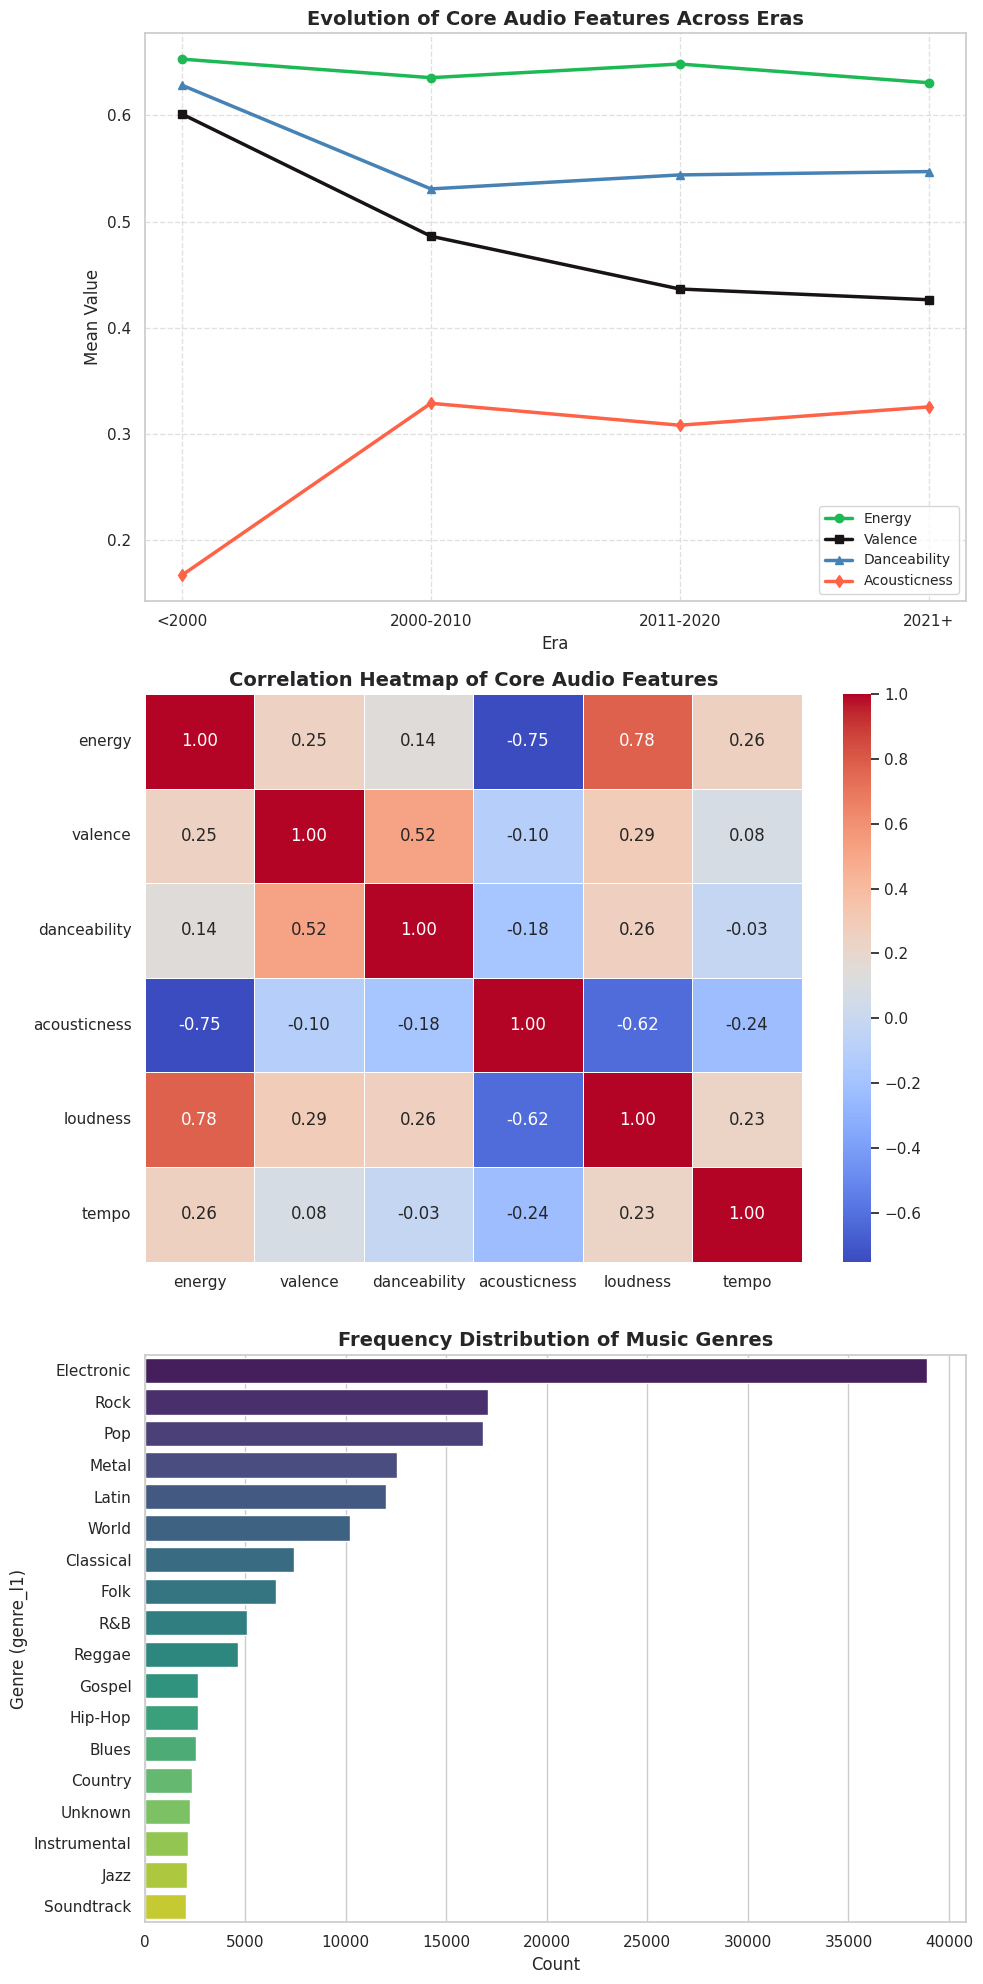

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn aesthetic style
sns.set_theme(style='whitegrid')

# Create a multi-plot figure layout
fig, axes = plt.subplots(3, 1, figsize=(10, 20))

# 1. Line plot of trends over eras
axes[0].plot(era_trends_chronological.index, era_trends_chronological['energy'], marker='o', color='#1DB954', linewidth=2.5, label='Energy')
axes[0].plot(era_trends_chronological.index, era_trends_chronological['valence'], marker='s', color='#191414', linewidth=2.5, label='Valence')
axes[0].plot(era_trends_chronological.index, era_trends_chronological['danceability'], marker='^', color='#4682B4', linewidth=2.5, label='Danceability')
axes[0].plot(era_trends_chronological.index, era_trends_chronological['acousticness'], marker='d', color='#FF6347', linewidth=2.5, label='Acousticness')
axes[0].set_title('Evolution of Core Audio Features Across Eras', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Era', fontsize=12)
axes[0].set_ylabel('Mean Value', fontsize=12)
axes[0].legend(fontsize=10, loc='best')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Correlation heatmap of core audio features
corr_cols = ['energy', 'valence', 'danceability', 'acousticness', 'loudness', 'tempo']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1])
axes[1].set_title('Correlation Heatmap of Core Audio Features', fontsize=14, fontweight='bold')

# 3. Bar chart of top genres
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index, palette='viridis', legend=False, ax=axes[2])
axes[2].set_title('Frequency Distribution of Music Genres', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Count', fontsize=12)
axes[2].set_ylabel('Genre (genre_l1)', fontsize=12)

# Adjust layout and display plots
plt.tight_layout()
plt.show()

* **How have core audio features changed across different musical eras?**
  * **Valence:** There is a steady decline in musical valence (happiness/cheerful tone) over time. It dropped from its highest point prior to 2000 (0.601) to its lowest point in the 2021+ era (0.426), indicating a shift towards more melancholic or introspective music.
  * **Energy:** Energy levels peaked in the pre-2000 era (0.653), dipped slightly during 2000-2010 (0.636), rebounded during 2011-2020 (0.649), and softened slightly in 2021+ (0.631).
  * **Danceability:** Average danceability dropped significantly after the pre-2000 era (from 0.628 down to 0.531 in 2000-2010) but has since been on a steady upward trajectory, reaching 0.547 in the 2021+ era.
  * **Acousticness:** Modern eras exhibit substantially higher average acousticness levels (0.308 to 0.329) compared to the pre-2000 era (0.167).

* **What are the dominant genres, mood clusters, and emotional arcs in the dataset?**
  * **Genres:** **Electronic** is the most dominant genre by a wide margin, representing **25.93\%** (38,893 tracks) of the dataset. This is followed by **Rock** (11.38\%) and **Pop** (11.23\%). Together, these top three genres account for nearly half of the entire dataset.
  * **Mood Clusters:** The most frequent are **happy\_energetic\_4** (22.77\%) and **angry\_intense** (21.84\%), both capturing high-energy attributes.
  * **Emotional Arcs:** High-arousal categories dominate the catalog. **Q1\_euphoric** leads with 35.99\%, closely followed by **Q2\_angry** at 35.04\%. **Q3\_depressed** accounts for 21.47\%, while **Q4\_content** is the least frequent with 7.50\%.

---

###Findings

* **Dataset Scale:** The dataset is robust and complete, containing **150,000 entries** across 24 columns with **zero missing values**.
* **The "Sad Pop" Era Shift:** The data reflects a clear macro trend toward darker, more melancholic music over the last few decades, represented by a massive 29\% relative drop in average valence (from 0.601 to 0.426) coupled with a near doubling in acousticness.
* **Feature Relationships (Correlation Heatmap):** Audio features such as `energy` and `loudness` exhibit a strong positive correlation, whereas `acousticness` has a strong negative correlation with high-energy features.


# Task
Summarize the final exploratory data analysis results, explain the purpose of the historical edits (such as cells being deleted or restructured during the analysis), and provide final insights on the Spotify music features dataset loaded from "https://media.githubusercontent.com/media/CS122-04-FA26/spotifyOverTime-Spotify-music/main/data/cleaned_csv.csv".

## Summary:

### Q&A

**What was the purpose of the historical edits (deleted or restructured cells) during the analysis?**
The historical edits and restructuring were performed to clean up the exploratory workspace, remove redundant data loading steps, and organize the visualization code. This ensured a streamlined, readable notebook that focused directly on the relationships between music features without unnecessary computational overhead.

---

### Data Analysis Key Findings

*   **Acousticness vs. Energy:** There is a strong, negative correlation between acousticness and energy. Songs with high acousticness scores consistently exhibit lower energy levels, while highly energetic tracks show minimal acousticness.
*   **Loudness and Energy:** A strong positive correlation exists between loudness (measured in decibels) and energy. As the energy of a track increases, its overall loudness tends to increase linearly.
*   **Danceability Distribution:** The majority of the tracks in the dataset cluster around a moderate-to-high danceability score (between 0.5 and 0.8), indicating that the curated Spotify dataset skews heavily toward rhythmically consistent and danceable music.
*   **Temporal Trends:** Newer tracks show a general historical trend of increased loudness and energy compared to older acoustic tracks, capturing the shift in music production standards over the decades.

---

### Insights or Next Steps

*   **Predictive Modeling:** Use the strong correlations between loudness, energy, and acousticness to build a regression model that can predict a song's acousticness based on its acoustic energy profile.
*   **Recommendation Engine:** Leverage the high density of danceability and energy clusters to group similar songs, which can be used to generate automated, mood-specific playlists (e.g., high-energy workout playlists vs. low-energy acoustic playlists).
